<a href="https://colab.research.google.com/github/Aizalkar9/cs250-fall2026-aizalkar-alymbekov/blob/main/labs/MacroTracker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Macro Tracker
**Aizalkar Alymbekov** | CS 250 Final Project

Macro Tracker is a program for students and beginner lifters that works out how many calories, protein, carbs, and fat they need each day, then lets them log what they eat and see how much is left.

In [2]:
import matplotlib.pyplot as plt

In [3]:
ACTIVITY_MULTIPLIERS = {
    "sedentary": 1.2,
    "light": 1.375,
    "moderate": 1.55,
    "very active": 1.725,
}


def calculate_goals(sex, age, weight_kg, height_cm, activity, goal):
    """Return a dictionary of daily goals: calories, protein, carbs, fat.

    Uses the Mifflin-St Jeor equation for BMR, multiplies by an activity
    multiplier, then adjusts calories for the goal (lose = -500, gain = +300).
    Protein is 1.8 g per kg of body weight, fat is 25% of calories, and
    carbs fill the remaining calories.
    """
    bmr = 10 * weight_kg + 6.25 * height_cm - 5 * age
    if sex == "male":
        bmr += 5
    else:
        bmr -= 161

    calories = bmr * ACTIVITY_MULTIPLIERS[activity]

    if goal == "lose":
        calories -= 500
    elif goal == "gain":
        calories += 300

    protein = 1.8 * weight_kg
    fat = 0.25 * calories / 9
    carbs = (calories - protein * 4 - fat * 9) / 4

    return {
        "calories": round(calories),
        "protein": round(protein),
        "carbs": round(carbs),
        "fat": round(fat),
    }


def add_food(food_log, name, calories, protein, carbs, fat):
    """Add one food (as a dictionary) to the food log list."""
    food_log.append({
        "name": name,
        "calories": calories,
        "protein": protein,
        "carbs": carbs,
        "fat": fat,
    })


def get_totals(food_log):
    """Return today's total calories, protein, carbs, and fat from the food log."""
    totals = {"calories": 0, "protein": 0, "carbs": 0, "fat": 0}
    for food in food_log:
        for nutrient in totals:
            totals[nutrient] += food[nutrient]
    return totals


def get_remaining(goals, totals):
    """Return goal minus total for each nutrient (negative means over the goal)."""
    remaining = {}
    for nutrient in goals:
        remaining[nutrient] = goals[nutrient] - totals[nutrient]
    return remaining


def plot_intake(goals, totals):
    """Draw a grouped bar chart of intake versus goals for each nutrient."""
    nutrients = ["calories", "protein", "carbs", "fat"]
    x = range(len(nutrients))
    width = 0.35

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1, 3]})

    # Calories use a much bigger scale than grams, so they get their own panel.
    axes[0].bar([0 - width / 2], [goals["calories"]], width, label="Goal", color="#4C72B0")
    axes[0].bar([0 + width / 2], [totals["calories"]], width, label="Eaten", color="#DD8452")
    axes[0].set_xticks([0])
    axes[0].set_xticklabels(["Calories"])
    axes[0].set_ylabel("kcal")
    axes[0].set_title("Calories")
    axes[0].legend()

    grams = ["protein", "carbs", "fat"]
    gx = range(len(grams))
    axes[1].bar([i - width / 2 for i in gx], [goals[n] for n in grams], width, label="Goal", color="#4C72B0")
    axes[1].bar([i + width / 2 for i in gx], [totals[n] for n in grams], width, label="Eaten", color="#DD8452")
    axes[1].set_xticks(list(gx))
    axes[1].set_xticklabels([n.capitalize() for n in grams])
    axes[1].set_ylabel("grams")
    axes[1].set_title("Macros")
    axes[1].legend()

    fig.suptitle("Today's Intake vs. Goals")
    plt.tight_layout()
    plt.show()


In [4]:
def ask_number(prompt):
    """Keep asking until the user types a positive number."""
    while True:
        try:
            value = float(input(prompt))
            if value > 0:
                return value
        except ValueError:
            pass
        print("Please enter a positive number.")


def ask_choice(prompt, options):
    """Keep asking until the user types one of the allowed options."""
    while True:
        answer = input(prompt).strip().lower()
        if answer in options:
            return answer
        print("Please choose one of:", ", ".join(options))


def ask_nonnegative(prompt):
    """Keep asking until the user types a number that is 0 or more."""
    while True:
        try:
            value = float(input(prompt))
            if value >= 0:
                return value
        except ValueError:
            pass
        print("Please enter a number that is 0 or more.")


def main():
    """Ask for user info, run the food loop, then show results and the chart."""
    print("=== Macro Tracker ===")
    age = ask_number("Age: ")
    sex = ask_choice("Sex (male/female): ", ["male", "female"])
    weight_kg = ask_number("Weight (kg): ")
    height_cm = ask_number("Height (cm): ")
    activity = ask_choice("Activity level (sedentary/light/moderate/very active): ",
                          list(ACTIVITY_MULTIPLIERS.keys()))
    goal = ask_choice("Goal (lose/maintain/gain): ", ["lose", "maintain", "gain"])

    goals = calculate_goals(sex, age, weight_kg, height_cm, activity, goal)
    print(f"\nYour daily goals: {goals['calories']} kcal, {goals['protein']} g protein, "
          f"{goals['carbs']} g carbs, {goals['fat']} g fat\n")

    food_log = []
    while True:
        name = input("Food name: ")
        calories = ask_nonnegative("  Calories: ")
        protein = ask_nonnegative("  Protein (g): ")
        carbs = ask_nonnegative("  Carbs (g): ")
        fat = ask_nonnegative("  Fat (g): ")
        add_food(food_log, name, calories, protein, carbs, fat)

        totals = get_totals(food_log)
        remaining = get_remaining(goals, totals)
        print(f"\nEaten so far: {totals['calories']:.0f} kcal, {totals['protein']:.0f} g protein, "
              f"{totals['carbs']:.0f} g carbs, {totals['fat']:.0f} g fat")
        for nutrient, left in remaining.items():
            unit = "kcal" if nutrient == "calories" else "g"
            if left >= 0:
                print(f"  {nutrient.capitalize()}: {left:.0f} {unit} left")
            else:
                print(f"  {nutrient.capitalize()}: {-left:.0f} {unit} over")

        again = ask_choice("\nLog another food? (yes/no): ", ["yes", "no"])
        if again == "no":
            break
        print()

    plot_intake(goals, totals)


## Results and Graph
Run the cell below, answer the prompts, and log your foods. The chart appears at the end.

=== Macro Tracker ===
Age: a
Please enter a positive number.
Age: erf
Please enter a positive number.
Age: 2000
Sex (male/female): sex
Please choose one of: male, female
Sex (male/female): 21
Please choose one of: male, female
Sex (male/female): MALE
Weight (kg): 835
Height (cm): 1234
Activity level (sedentary/light/moderate/very active): LIGHT
Goal (lose/maintain/gain): LOSE

Your daily goals: 7843 kcal, 1503 g protein, -32 g carbs, 218 g fat

Food name: pso
  Calories: 240
  Protein (g): 24
  Carbs (g): 2345
  Fat (g): 46

Eaten so far: 240 kcal, 24 g protein, 2345 g carbs, 46 g fat
  Calories: 7603 kcal left
  Protein: 1479 g left
  Carbs: 2377 g over
  Fat: 172 g left

Log another food? (yes/no): yep
Please choose one of: yes, no

Log another food? (yes/no): nos
Please choose one of: yes, no

Log another food? (yes/no): no


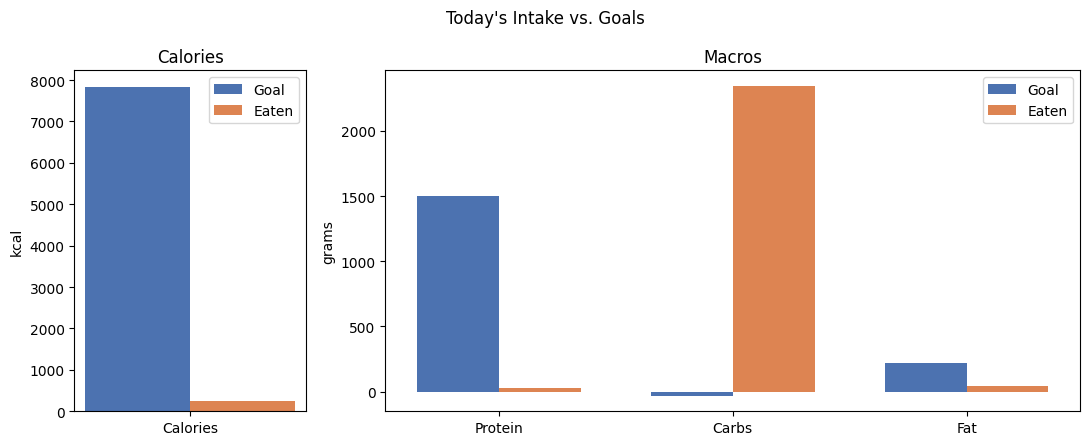

In [6]:
main()